# Robust decisions under declared ambiguity

Family 30. An ellipsoid describes uncertain means, while finite-support KL ambiguity changes scenario probabilities. Neither adds unmodeled tail outcomes. Zero nominal mass stays zero under KL(q||p).

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 30: robust mean ambiguity, CVaR and finite-support KL ambiguity."""
import numpy as np
from convexity.math import robust

mean = np.array([.05, .09])
covariance = np.array([[.01, .002], [.002, .04]])
for radius in (0., .2, 1.):
    result = robust.robust_allocation(mean, covariance, robust.Ellipsoid(mean, [[.01, 0], [0, .05]], radius), aversion=2.)
    print('Ambiguity radius:', radius, 'allocation:', result.solution)
returns = [[.1, -.2], [-.1, .2], [.05, .08]]
print('Mean-CVaR allocation:', robust.mean_cvar(returns, level=.8).solution)
for radius in (0., .1, 1.):
    result = robust.kl_worst_case([0., 2., 10.], radius, weights=[.7, .25, .05])
    print('KL radius:', radius, 'worst loss:', result.objective, 'adversarial masses:', result.solution)


Ambiguity radius: 0.0 allocation: [0.39130438 0.60869562]
Ambiguity radius: 0.2 allocation: [0.49382392 0.50617608]
Ambiguity radius: 1.0 allocation: [0.77603903 0.22396097]
Mean-CVaR allocation: [0.66666667 0.33333333]
KL radius: 0.0 worst loss: 1.0 adversarial masses: [0.7  0.25 0.05]
KL radius: 0.1 worst loss: 2.213194243773806 adversarial masses: [0.56425809 0.26802811 0.1677138 ]
KL radius: 1.0 worst loss: 5.852981567680512 adversarial masses: [0.26588597 0.18601983 0.54809419]


## Ambiguity changes allocations and worst-case losses

The second asset has greater mean uncertainty, so its allocation changes with ellipsoid radius. Increasing the KL radius can only increase the worst expected loss, approaching the worst supported outcome.

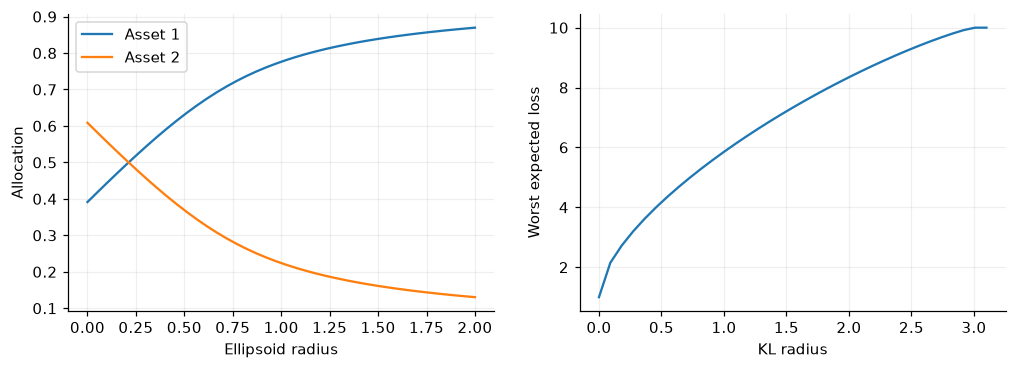

In [3]:
radii = np.linspace(0, 2, 40)
allocations = np.array([robust.robust_allocation(mean, covariance,
    robust.Ellipsoid(mean, [[.01, 0], [0, .05]], radius), aversion=2.).solution for radius in radii])
kl_radii = np.linspace(0, 3.1, 35)
worst = [robust.kl_worst_case([0., 2., 10.], radius, weights=[.7, .25, .05]).objective for radius in kl_radii]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(radii, allocations[:, 0], label='Asset 1'); axes[0].plot(radii, allocations[:, 1], label='Asset 2')
axes[0].set(xlabel='Ellipsoid radius', ylabel='Allocation'); axes[0].legend()
axes[1].plot(kl_radii, worst); axes[1].set(xlabel='KL radius', ylabel='Worst expected loss'); plt.show()

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.